<a href="https://colab.research.google.com/github/APosokhova893/python_basics/blob/main/16_2_%D0%9F%D1%80%D0%BE%D0%B3%D0%BD%D0%BE%D0%B7%D1%83%D0%B2%D0%B0%D0%BD%D0%BD%D1%8F_%D0%BA%D1%80%D0%B5%D0%B4%D0%B8%D1%82%D0%BD%D0%BE%D0%B3%D0%BE_%D1%80%D0%B8%D0%B7%D0%B8%D0%BA%D1%83_ipynb%22.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Домашнє завдання: Прогнозування кредитного ризику

## Мета завдання
Застосувати знання з лекції для побудови моделі логістичної регресії, що прогнозує ймовірність дефолту за кредитом, іншими словами, що людина не поверне кредит. Ви пройдете весь цикл: від дослідницького аналізу до оцінки якості класифікаційної моделі.

## Опис датасету
**Credit Risk Dataset** містить інформацію про 32,000+ позичальників з такими параметрами:
- **person_age**: Вік позичальника
- **person_income**: Річний дохід
- **person_home_ownership**: Тип володіння житлом
- **person_emp_length**: Стаж роботи (в роках)
- **loan_intent**: Мета кредиту
- **loan_grade**: Кредитний рейтинг (A - кращий, F - гірший)
- **loan_amnt**: Сума кредиту
- **loan_int_rate**: Процентна ставка
- **loan_status**: Статус кредиту (0 = сплачено, 1 = дефолт) - **цільова змінна**
- **loan_percent_income**: Відношення кредиту до доходу
- **cb_person_default_on_file**: Історія дефолтів (Y/N)
- **cb_person_cred_hist_length**: Довжина кредитної історії

---

## Завдання 1: Завантаження та перший огляд даних (1 бал)

**Що потрібно зробити:**
1. Завантажте дані з файлу `credit_risk_dataset.csv`
2. Виведіть розмір датасету
3. Покажіть перші 5 рядків
4. Виведіть загальну інформацію про дані (кількість записів, типи колонок)
5. Перевірте розподіл цільової змінної (відсотк даних для кожного класу)

Дайте висновок, це задача збалансованої чи незбалансованої класифікації.


In [1]:
import pandas as pd
import numpy as np
import plotly.express as px
import plotly.graph_objects as go
from plotly.subplots import make_subplots

pd.set_option('display.max_columns', None)

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
df = pd.read_csv('/content/drive/MyDrive/Data Analytics Course/modul 16/credit_risk_dataset.csv')

In [4]:
df.shape

(32581, 12)

In [5]:
df.head()

,person_age,person_income,person_home_ownership,person_emp_length,loan_intent,loan_grade,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_default_on_file,cb_person_cred_hist_length
0,22,59000,RENT,123.0,PERSONAL,D,35000,16.02,1,0.59,Y,3
1,21,9600,OWN,5.0,EDUCATION,B,1000,11.14,0,0.10,N,2
2,25,9600,MORTGAGE,1.0,MEDICAL,C,5500,12.87,1,0.57,N,3
3,23,65500,RENT,4.0,MEDICAL,C,35000,15.23,1,0.53,N,2
4,24,54400,RENT,8.0,MEDICAL,C,35000,14.27,1,0.55,Y,4


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32581 entries, 0 to 32580
Data columns (total 12 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   person_age                  32581 non-null  int64  
 1   person_income               32581 non-null  int64  
 2   person_home_ownership       32581 non-null  object 
 3   person_emp_length           31686 non-null  float64
 4   loan_intent                 32581 non-null  object 
 5   loan_grade                  32581 non-null  object 
 6   loan_amnt                   32581 non-null  int64  
 7   loan_int_rate               29465 non-null  float64
 8   loan_status                 32581 non-null  int64  
 9   loan_percent_income         32581 non-null  float64
 10  cb_person_default_on_file   32581 non-null  object 
 11  cb_person_cred_hist_length  32581 non-null  int64  
dtypes: float64(3), int64(5), object(4)
memory usage: 3.0+ MB


In [7]:
df['loan_status'].value_counts(normalize=True) * 100

,proportion
loan_status,
0,78.183604
1,21.816396


У датасеті 78,18% кредитів без дефолту та 21,82% кредитів із дефолтом. Отже, класи незбалансовані, оскільки кредитів без дефолту значно більше. Це потрібно враховувати під час навчання та оцінювання моделі.


---

## Завдання 2: Дослідницький аналіз даних (EDA) (4 бали)

**Що потрібно зробити:**
1. Обчисліть відсоток пропущених значень в колонках. За наявності пропущених значень - заповніть їх медіаною для числових колонок і найбільш частим значеннмя для категоріальних.
2. Проаналізуйте розподіл числових змінних.
3. Знайдіть та обробіть викиди в колонці person_income з допомогою [Interquartile range](https://uk.wikipedia.org/wiki/%D0%9C%D1%96%D0%B6%D0%BA%D0%B2%D0%B0%D1%80%D1%82%D0%B8%D0%BB%D1%8C%D0%BD%D0%B8%D0%B9_%D1%80%D0%BE%D0%B7%D0%BC%D0%B0%D1%85).
4. Проаналізуйте категоріальні змінні відносно цільової та частоту зустрічання різних значень в них.
5. Візуалізуйте взаємозв'язок ознак з цільовою змінною.


In [8]:
df.isnull().mean() * 100

,0
person_age,0.000000
person_income,0.000000
person_home_ownership,0.000000
person_emp_length,2.747000
loan_intent,0.000000
loan_grade,0.000000
loan_amnt,0.000000
loan_int_rate,9.563856
loan_status,0.000000
loan_percent_income,0.000000


In [9]:
df['person_emp_length'] = df['person_emp_length'].fillna(df['person_emp_length'].median())

In [10]:
df['loan_int_rate'] = df['loan_int_rate'].fillna(df['loan_int_rate'].median())

In [11]:
df.isnull().sum()

,0
person_age,0
person_income,0
person_home_ownership,0
person_emp_length,0
loan_intent,0
loan_grade,0
loan_amnt,0
loan_int_rate,0
loan_status,0
loan_percent_income,0


In [13]:
df.describe()

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
count,32581.000000,3.258100e+04,32581.000000,32581.000000,32581.000000,32581.000000,32581.000000,32581.000000
mean,27.734600,6.607485e+04,4.767994,9589.371106,11.009620,0.218164,0.170203,5.804211
std,6.348078,6.198312e+04,4.087372,6322.086646,3.081611,0.413006,0.106782,4.055001
min,20.000000,4.000000e+03,0.000000,500.000000,5.420000,0.000000,0.000000,2.000000
25%,23.000000,3.850000e+04,2.000000,5000.000000,8.490000,0.000000,0.090000,3.000000
50%,26.000000,5.500000e+04,4.000000,8000.000000,10.990000,0.000000,0.150000,4.000000
75%,30.000000,7.920000e+04,7.000000,12200.000000,13.110000,0.000000,0.230000,8.000000
max,144.000000,6.000000e+06,123.000000,35000.000000,23.220000,1.000000,0.830000,30.000000


In [14]:
px.histogram(df, x='person_income')

In [15]:
numeric_cols = df.select_dtypes(include='number').columns
numeric_cols

Index(['person_age', 'person_income', 'person_emp_length', 'loan_amnt',
       'loan_int_rate', 'loan_status', 'loan_percent_income',
       'cb_person_cred_hist_length'],
      dtype='object')

In [16]:
px.box(df, y='person_income')

In [17]:
Q1 = df['person_income'].quantile(0.25)
print(Q1)

38500.0


In [18]:
Q3 = df['person_income'].quantile(0.75)
print(Q3)

79200.0


In [19]:
IQR = Q3 - Q1
print(IQR)

40700.0


In [20]:
lower_bound = Q1 - 1.5 * IQR
print(lower_bound)

-22550.0


In [21]:
upper_bound = Q3 + 1.5 * IQR
print(upper_bound)

140250.0


In [22]:
outliers = df[df['person_income'] > upper_bound]
print(len(outliers))

1484


In [23]:
df_clean=df.copy()

In [24]:
df_clean['person_income'] = df_clean['person_income'].clip(upper=upper_bound)

In [25]:
df_clean['person_income'].max()

140250

In [26]:
df_clean['person_home_ownership'].value_counts()

,count
person_home_ownership,
RENT,16446
MORTGAGE,13444
OWN,2584
OTHER,107


In [27]:
df_clean.groupby('person_home_ownership')['loan_status'].mean() * 100

,loan_status
person_home_ownership,
MORTGAGE,12.570663
OTHER,30.841121
OWN,7.469040
RENT,31.569987


In [28]:
df_clean['loan_grade'].value_counts()

,count
loan_grade,
A,10777
B,10451
C,6458
D,3626
E,964
F,241
G,64


In [29]:
df_clean.groupby('loan_grade')['loan_status'].mean() * 100

,loan_status
loan_grade,
A,9.956389
B,16.275954
C,20.733973
D,59.045780
E,64.419087
F,70.539419
G,98.437500


In [30]:
df_clean.select_dtypes(include='object').columns

Index(['person_home_ownership', 'loan_intent', 'loan_grade',
       'cb_person_default_on_file'],
      dtype='object')

In [31]:
df_clean['loan_intent'].value_counts()

,count
loan_intent,
EDUCATION,6453
MEDICAL,6071
VENTURE,5719
PERSONAL,5521
DEBTCONSOLIDATION,5212
HOMEIMPROVEMENT,3605


In [32]:
df_clean.groupby('loan_intent')['loan_status'].mean() * 100

,loan_status
loan_intent,
DEBTCONSOLIDATION,28.587874
EDUCATION,17.216798
HOMEIMPROVEMENT,26.102635
MEDICAL,26.700708
PERSONAL,19.887702
VENTURE,14.810282


In [33]:
df_clean['cb_person_default_on_file'].value_counts()

,count
cb_person_default_on_file,
N,26836
Y,5745


In [34]:
df_clean.groupby('cb_person_default_on_file')['loan_status'].mean() * 100

,loan_status
cb_person_default_on_file,
N,18.393203
Y,37.806789


In [39]:
fig = px.bar(
    df_clean.groupby('loan_grade', as_index=False)['loan_status'].mean(),
    x='loan_grade',
    y='loan_status',
    title='Залежність статусу кредиту від кредитного рейтингу',
    color_discrete_sequence=['royalblue']
)

fig.show()


---

## Завдання 3: Аналіз кореляцій та Feature Engineering (3 бали)

**Що потрібно зробити:**
1. Побудуйте матрицю кореляцій для числових змінних.
2. Закодуйте категоріальні змінні.
3. Виберіть фінальний набір ознак, можна лишити всі, якщо ви вважаєте, що це - доцільно.



In [40]:
numeric_df = df_clean.select_dtypes(include='number')
numeric_df.head()

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
0,22,59000,123.0,35000,16.02,1,0.59,3
1,21,9600,5.0,1000,11.14,0,0.10,2
2,25,9600,1.0,5500,12.87,1,0.57,3
3,23,65500,4.0,35000,15.23,1,0.53,2
4,24,54400,8.0,35000,14.27,1,0.55,4


In [41]:
corr_matrix = numeric_df.corr()
corr_matrix

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length
person_age,1.000000,0.117981,0.161454,0.050787,0.011853,-0.021629,-0.042411,0.859133
person_income,0.117981,1.000000,0.198751,0.420091,-0.017050,-0.245934,-0.367245,0.093901
person_emp_length,0.161454,0.198751,1.000000,0.113851,-0.051262,-0.082182,-0.054134,0.143069
loan_amnt,0.050787,0.420091,0.113851,1.000000,0.139483,0.105376,0.572612,0.041967
loan_int_rate,0.011853,-0.017050,-0.051262,0.139483,1.000000,0.319360,0.114514,0.015762
loan_status,-0.021629,-0.245934,-0.082182,0.105376,0.319360,1.000000,0.379366,-0.015529
loan_percent_income,-0.042411,-0.367245,-0.054134,0.572612,0.114514,0.379366,1.000000,-0.031690
cb_person_cred_hist_length,0.859133,0.093901,0.143069,0.041967,0.015762,-0.015529,-0.031690,1.000000


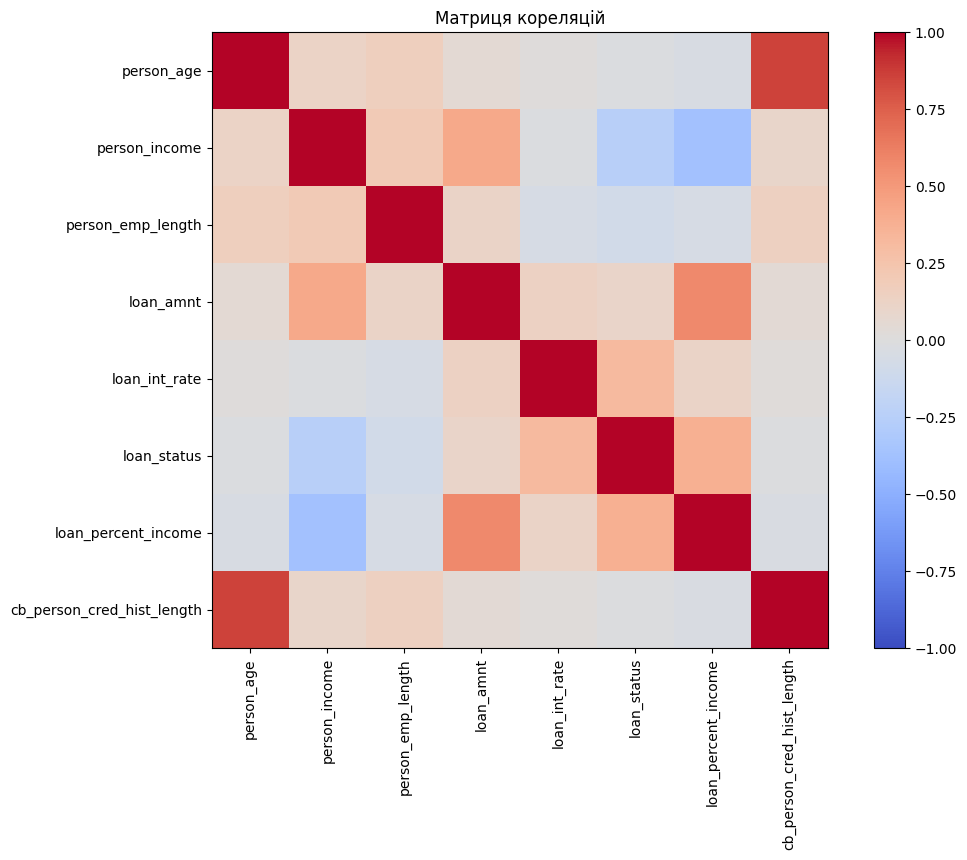

In [42]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 8))
plt.imshow(corr_matrix, cmap='coolwarm', vmin=-1, vmax=1)
plt.colorbar()

plt.xticks(range(len(corr_matrix.columns)), corr_matrix.columns, rotation=90)
plt.yticks(range(len(corr_matrix.columns)), corr_matrix.columns)

plt.title('Матриця кореляцій')
plt.show()

In [43]:
df_encoded = pd.get_dummies(df_clean, dtype=int)

df_encoded.head()

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_status,loan_percent_income,cb_person_cred_hist_length,person_home_ownership_MORTGAGE,person_home_ownership_OTHER,person_home_ownership_OWN,person_home_ownership_RENT,loan_intent_DEBTCONSOLIDATION,loan_intent_EDUCATION,loan_intent_HOMEIMPROVEMENT,loan_intent_MEDICAL,loan_intent_PERSONAL,loan_intent_VENTURE,loan_grade_A,loan_grade_B,loan_grade_C,loan_grade_D,loan_grade_E,loan_grade_F,loan_grade_G,cb_person_default_on_file_N,cb_person_default_on_file_Y
0,22,59000,123.0,35000,16.02,1,0.59,3,0,0,0,1,0,0,0,0,1,0,0,0,0,1,0,0,0,0,1
1,21,9600,5.0,1000,11.14,0,0.10,2,0,0,1,0,0,1,0,0,0,0,0,1,0,0,0,0,0,1,0
2,25,9600,1.0,5500,12.87,1,0.57,3,1,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,1,0
3,23,65500,4.0,35000,15.23,1,0.53,2,0,0,0,1,0,0,0,1,0,0,0,0,1,0,0,0,0,1,0
4,24,54400,8.0,35000,14.27,1,0.55,4,0,0,0,1,0,0,0,1,0,0,0,0,1,0,0,0,0,0,1


In [44]:
X = df_encoded.drop(columns=['loan_status'])

X.head()

,person_age,person_income,person_emp_length,loan_amnt,loan_int_rate,loan_percent_income,cb_person_cred_hist_length,person_home_ownership_MORTGAGE,person_home_ownership_OTHER,person_home_ownership_OWN,person_home_ownership_RENT,loan_intent_DEBTCONSOLIDATION,loan_intent_EDUCATION,loan_intent_HOMEIMPROVEMENT,loan_intent_MEDICAL,loan_intent_PERSONAL,loan_intent_VENTURE,loan_grade_A,loan_grade_B,loan_grade_C,loan_grade_D,loan_grade_E,loan_grade_F,loan_grade_G,cb_person_default_on_file_N,cb_person_default_on_file_Y
0,22,59000,123.0,35000,16.02,0.59,3,0,0,0,1,0,0,0,0,1,0,0,0,0,1,0,0,0,0,1
1,21,9600,5.0,1000,11.14,0.10,2,0,0,1,0,0,1,0,0,0,0,0,1,0,0,0,0,0,1,0
2,25,9600,1.0,5500,12.87,0.57,3,1,0,0,0,0,0,0,1,0,0,0,0,1,0,0,0,0,1,0
3,23,65500,4.0,35000,15.23,0.53,2,0,0,0,1,0,0,0,1,0,0,0,0,1,0,0,0,0,1,0
4,24,54400,8.0,35000,14.27,0.55,4,0,0,0,1,0,0,0,1,0,0,0,0,1,0,0,0,0,0,1



---

## Завдання 4: Підготовка даних та навчання моделі (3 бали)

**Що потрібно зробити:**
1. Розділіть дані на X та y
2. Поділіть на навчальну та тестову вибірки
3. Застосуйте масштабування
4. Навчіть модель логістичної регресії
5. Зробіть прогнози на тренувальній та тестовій вибірках.



In [46]:
y = df_encoded['loan_status']
y.head()

,loan_status
0,1
1,0
2,1
3,1
4,1


In [47]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [48]:
print(X_train.shape)
print(X_test.shape)

(26064, 26)
(6517, 26)


In [49]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

In [53]:
numeric_cols = [
    'person_age',
    'person_income',
    'person_emp_length',
    'loan_amnt',
    'loan_int_rate',
    'loan_percent_income',
    'cb_person_cred_hist_length'
]

In [54]:
X_train_scaled = X_train.copy()

X_train_scaled[numeric_cols] = scaler.fit_transform(X_train[numeric_cols])

In [52]:
print(X_train.columns.tolist())

['person_age', 'person_income', 'person_emp_length', 'loan_amnt', 'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length', 'person_home_ownership_MORTGAGE', 'person_home_ownership_OTHER', 'person_home_ownership_OWN', 'person_home_ownership_RENT', 'loan_intent_DEBTCONSOLIDATION', 'loan_intent_EDUCATION', 'loan_intent_HOMEIMPROVEMENT', 'loan_intent_MEDICAL', 'loan_intent_PERSONAL', 'loan_intent_VENTURE', 'loan_grade_A', 'loan_grade_B', 'loan_grade_C', 'loan_grade_D', 'loan_grade_E', 'loan_grade_F', 'loan_grade_G', 'cb_person_default_on_file_N', 'cb_person_default_on_file_Y']


In [55]:
X_test_scaled = X_test.copy()

X_test_scaled[numeric_cols] = scaler.transform(X_test[numeric_cols])

In [56]:
from sklearn.linear_model import LogisticRegression

model = LogisticRegression(max_iter=1000)

In [57]:
model.fit(X_train_scaled, y_train)

LogisticRegression(max_iter=1000)

In [58]:
y_train_pred = model.predict(X_train_scaled)

y_train_pred[:10]

array([0, 0, 0, 0, 0, 0, 0, 1, 0, 0])

In [59]:
y_test_pred = model.predict(X_test_scaled)

y_test_pred[:10]

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 1])


---

## Завдання 5: Оцінка якості моделі (4 бали)

**Що потрібно зробити:**
1. Побудуйте confusion matrix.
2. Обчисліть основні метрики (accuracy, precision, recall, f1).
3. Побудуйте ROC-криву та обчисліть AUC
4. Проаналізуйте важливість ознак.
5. Зробіть висновки про якість моделі та які ознаки найбільше впливають на прогноз.


In [60]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_test, y_test_pred)

print(cm)

[[4849  246]
 [ 623  799]]


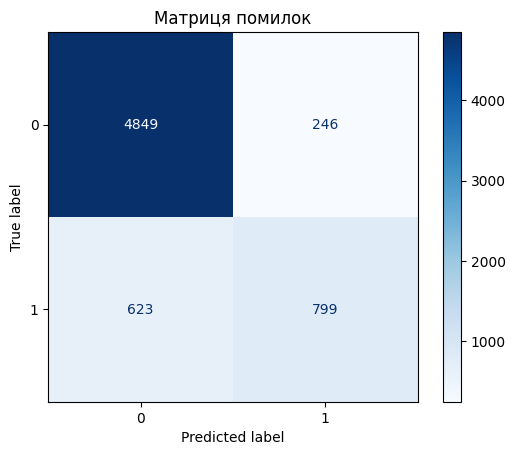

In [62]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

disp = ConfusionMatrixDisplay(confusion_matrix=cm)
disp.plot(cmap='Blues')

plt.title('Матриця помилок')
plt.show()

In [63]:
from sklearn.metrics import accuracy_score

accuracy = accuracy_score(y_test, y_test_pred)

print("Accuracy:", accuracy)

Accuracy: 0.8666564370108946


In [64]:
from sklearn.metrics import precision_score

precision = precision_score(y_test, y_test_pred)

print("Precision:", precision)

Precision: 0.7645933014354067


In [66]:
from sklearn.metrics import recall_score

recall = recall_score(y_test, y_test_pred)

print("Recall:", recall)

Recall: 0.5618846694796061


In [68]:
from sklearn.metrics import f1_score

f1 = f1_score(y_test, y_test_pred)

print("F1:", f1)

F1: 0.6477503040129712


In [69]:
y_test_proba = model.predict_proba(X_test_scaled)[:, 1]

y_test_proba[:10]

array([0.11350126, 0.08929287, 0.00765608, 0.07301483, 0.00662778,
       0.11991064, 0.0268036 , 0.0466548 , 0.01572284, 0.82608343])

In [70]:
from sklearn.metrics import roc_curve

fpr, tpr, thresholds = roc_curve(y_test, y_test_proba)

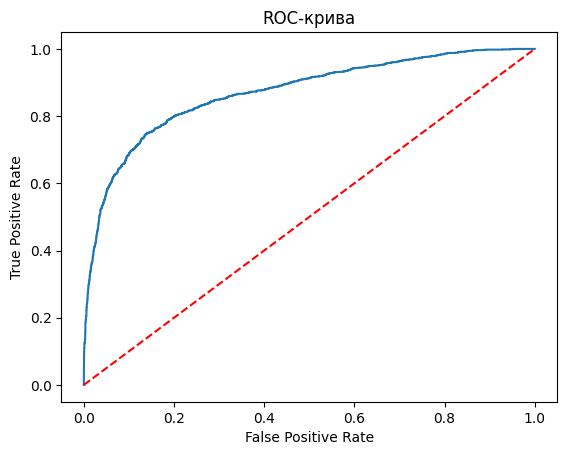

In [76]:
plt.plot(fpr, tpr)
plt.plot([0, 1], [0, 1], 'r--')
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC-крива')
plt.show()

In [72]:
from sklearn.metrics import roc_auc_score
auc = roc_auc_score(y_test, y_test_proba)
print("AUC:", auc)

AUC: 0.8698139015526377


In [75]:
feature_importance = pd.DataFrame({
    'feature': X.columns,
    'coefficient': model.coef_[0],
    'abs_coefficient': np.abs(model.coef_[0])
}).sort_values('abs_coefficient', ascending=False)

feature_importance

,feature,coefficient,abs_coefficient
23,loan_grade_G,2.864389,2.864389
17,loan_grade_A,-2.043868,2.043868
18,loan_grade_B,-1.808554,1.808554
9,person_home_ownership_OWN,-1.650899,1.650899
19,loan_grade_C,-1.647816,1.647816
5,loan_percent_income,1.257134,1.257134
22,loan_grade_F,1.105463,1.105463
10,person_home_ownership_RENT,0.813094,0.813094
21,loan_grade_E,0.712646,0.712646
16,loan_intent_VENTURE,-0.711346,0.711346


Модель показала досить хороші результати: Accuracy — 86,7%, AUC — 0,87. Але Recall становить лише 56,2%, тобто модель пропускає частину клієнтів, які мають ризик дефолту. Найбільше з прогнозом пов’язані кредитні рейтинги G, A та B. Отже, модель працює непогано, але її здатність виявляти ризикових клієнтів потрібно покращити.


---

## Завдання 6: Оптимізація порогу та бізнес-аналіз (2 бали)

**Що потрібно зробити:**
1. Проаналізуйте метрики precision, recall, F1 при різних порогах класифікації (мінімум - 5 різних порогів). Візуалізуйте як змінюються метрики якості при зміні порогу.
2. Оберіть оптимальний поріг для бізнес-задачі - можна обрати виходячи з попереднього пункту, або додати своїх роздумів і обрати інший.



In [77]:
thresholds = [0.1, 0.3, 0.5, 0.7, 0.9]

print(thresholds)

[0.1, 0.3, 0.5, 0.7, 0.9]


In [80]:
for threshold in thresholds:
    y_pred = (y_test_proba >= threshold).astype(int)
    print("Поріг:", threshold)
    print("Precision:", precision_score(y_test, y_pred))
    print("Recall:", recall_score(y_test, y_pred))
    print("F1:", f1_score(y_test, y_pred))
    print()

Поріг: 0.1
Precision: 0.3804878048780488
Recall: 0.8776371308016878
F1: 0.5308379413015738

Поріг: 0.3
Precision: 0.6235438381361128
Recall: 0.7151898734177216
F1: 0.6662299377661317

Поріг: 0.5
Precision: 0.7645933014354067
Recall: 0.5618846694796061
F1: 0.6477503040129712

Поріг: 0.7
Precision: 0.8559322033898306
Recall: 0.3551336146272855
F1: 0.5019880715705766

Поріг: 0.9
Precision: 0.9381443298969072
Recall: 0.1279887482419128
F1: 0.22524752475247525



In [84]:
precision_values = [0.3805, 0.6235, 0.7646, 0.8559, 0.9381]
recall_values = [0.8776, 0.7152, 0.5619, 0.3551, 0.1280]
f1_values = [0.5308, 0.6662, 0.6478, 0.5020, 0.2252]

In [85]:
metrics_df = pd.DataFrame({
    'threshold': thresholds,
    'precision': precision_values,
    'recall': recall_values,
    'f1': f1_values
})

metrics_df

,threshold,precision,recall,f1
0,0.1,0.3805,0.8776,0.5308
1,0.3,0.6235,0.7152,0.6662
2,0.5,0.7646,0.5619,0.6478
3,0.7,0.8559,0.3551,0.5020
4,0.9,0.9381,0.1280,0.2252


In [86]:
fig = px.line(
    metrics_df.melt(id_vars='threshold'),
    x='threshold',
    y='value',
    color='variable',
    markers=True,
    title='Метрики при різних порогах класифікації',
    labels={
        'threshold': 'Поріг',
        'value': 'Значення метрики',
        'variable': 'Метрика'
    }
)

fig.show()

Для цієї бізнес-задачі я обрала поріг 0.3, оскільки банку важливо виявляти якомога більше клієнтів із ризиком неповернення кредиту. При цьому порозі Recall становить 71,5%, а F1 — 66,6%, що є найкращим результатом F1 серед перевірених порогів. Хоча Precision нижчий, ніж при порозі 0.5, модель виявляє більше ризикових клієнтів. Тому поріг 0.3 є доцільним вибором для цієї задачі.


---

## Завдання 7 (Опціональне): Покращення моделі та висновки (2 бали)

**Що потрібно зробити:**

На цих же даних навчіть DecisionTreeClassifier та RandomForestClassifier. Яка з трьох моделей дає найкращий результат на тестовому наборі?

Поріг класифікації можна для порівняння якостей моделей використовувати стандартний 0.5, або той, що ви виявили, як оптимальний на попередньому кроці.


In [87]:
from sklearn.tree import DecisionTreeClassifier

In [88]:
tree_model = DecisionTreeClassifier(random_state=42)

In [89]:
tree_model.fit(X_train_scaled, y_train)

DecisionTreeClassifier(random_state=42)

In [90]:
y_tree_pred = tree_model.predict(X_test_scaled)

y_tree_pred[:10]

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 1])

In [91]:
print("Accuracy:", accuracy_score(y_test, y_tree_pred))
print("Precision:", precision_score(y_test, y_tree_pred))
print("Recall:", recall_score(y_test, y_tree_pred))
print("F1:", f1_score(y_test, y_tree_pred))

Accuracy: 0.8858370415835507
Precision: 0.7253989361702128
Recall: 0.7672292545710268
F1: 0.745727956254272


In [92]:
from sklearn.ensemble import RandomForestClassifier

In [93]:
forest_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

In [94]:
forest_model.fit(X_train_scaled, y_train)

RandomForestClassifier(random_state=42)

In [95]:
y_forest_pred = forest_model.predict(X_test_scaled)

y_forest_pred[:10]

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 1])

In [96]:
print("Accuracy:", accuracy_score(y_test, y_forest_pred))
print("Precision:", precision_score(y_test, y_forest_pred))
print("Recall:", recall_score(y_test, y_forest_pred))
print("F1:", f1_score(y_test, y_forest_pred))

Accuracy: 0.9335583857603191
Precision: 0.9714013346043852
Recall: 0.7165963431786216
F1: 0.8247673006879805


Було навчено та порівняно три моделі: Logistic Regression, Decision Tree та Random Forest.

Найкращі загальні результати показала модель Random Forest: Accuracy — 93,4%, Precision — 97,1%, F1 — 82,5%.

Decision Tree показала найвищий Recall — 76,7%, тобто краще виявляє ризикових клієнтів.

Отже, за сукупністю метрик найкращою виявилася модель Random Forest. Проте, якщо для банку найважливіше не пропускати клієнтів із ризиком дефолту, варто також розглянути Decision Tree.